In [ ]:
import os
import json
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

import main_analysis as ma

In [2]:
RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

MODELS_INFO_CSV_PATH = f'{RESULTS_DIR}/models_info.csv'
LOCALIZATION_VALIDATION_GS_CSV_DIR = f'{RESULTS_DIR}/localization_validation_grillspector.csv'
LOCALIZATION_VALIDATION_KW_CSV_DIR = f'{RESULTS_DIR}/localization_validation_kanwisher.csv'
LOCALIZATION_VALIDATION_KWGRAY_CSV_DIR = f'{RESULTS_DIR}/localization_validation_kanwishergrayscale.csv'
SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'
LOCALIZEREFFECT_CSV_PATH = f'{RESULTS_DIR}/localizer_effect_correlations_nsd515.csv'
TTHRESHOLDEFFECT_CSV_PATH = f'{RESULTS_DIR}/tthreshold_effect_correlations_nsd515.csv'

# Localization Validation

In [5]:
# Grill-Spector localization validation
plot_dir = f'{PLOTS_DIR}/localization_validation'
os.makedirs(plot_dir, exist_ok=True)

localization_validation_df = pd.read_csv(LOCALIZATION_VALIDATION_GS_CSV_DIR)

frois = localization_validation_df['model_froi'].unique()

annotate_models = False

for froi in frois:
    froi_df = localization_validation_df[localization_validation_df['model_froi'] == froi]
    localization_tvalues = froi_df['localization_tvalue'].values
    validation_tvalues = froi_df['validation_tvalue'].values
    n_models = len(validation_tvalues)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    m, b = np.polyfit(localization_tvalues, validation_tvalues, 1)
    plt.plot(localization_tvalues, m*localization_tvalues + b, color='k', alpha=0.5)
    plt.scatter(localization_tvalues, validation_tvalues, color='red', alpha=1, zorder=2)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(localization_tvalues, validation_tvalues)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    if annotate_models:
        best_model_idx = np.argmax(validation_tvalues)
        worst_model_idx = np.argmin(validation_tvalues)
        median_model_idx = np.argsort(validation_tvalues)[len(validation_tvalues) // 2]
        best_model_name = froi_df.iloc[best_model_idx]['model_name']
        worst_model_name = froi_df.iloc[worst_model_idx]['model_name']
        median_model_name = froi_df.iloc[median_model_idx]['model_name']

        plt.annotate(f'Best: {best_model_name}', xy=(localization_tvalues[best_model_idx], validation_tvalues[best_model_idx]), 
                     xytext=(localization_tvalues[best_model_idx]+5, validation_tvalues[best_model_idx]+5),
                     arrowprops=dict(facecolor='green', shrink=0.05))
        plt.annotate(f'Worst: {worst_model_name}', xy=(localization_tvalues[worst_model_idx], validation_tvalues[worst_model_idx]), 
                     xytext=(localization_tvalues[worst_model_idx]-5, validation_tvalues[worst_model_idx]-5),
                     arrowprops=dict(facecolor='red', shrink=0.05))
        plt.annotate(f'Median: {median_model_name}', xy=(localization_tvalues[median_model_idx], validation_tvalues[median_model_idx]), 
                     xytext=(localization_tvalues[median_model_idx]+5, validation_tvalues[median_model_idx]+5),
                     arrowprops=dict(facecolor='orange', shrink=0.05))

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.yticks(np.arange(5, int(max(validation_tvalues)+5), 5))
    xticks_lowlim = int(np.floor(min(localization_tvalues) / 20) * 20)
    plt.xticks(
        np.arange(
            xticks_lowlim,
            int(max(localization_tvalues) + 20), 20
        )
    )
    plt.xlabel('Localization t-values (Grill-Spector, t>7)')
    plt.ylabel('Validation t-values (Konkle)')
    plt.title(f'{froi} Localization: t-value of pref. vs. all others')
    plt.savefig(f'{plot_dir}/localization_validation_grillspector_{froi}.pdf')
    # plt.show()
    plt.close()

In [ ]:
# Kanwisher localization validation
plot_dir = f'{PLOTS_DIR}/localization_validation'
os.makedirs(plot_dir, exist_ok=True)

localization_validation_df = pd.read_csv(LOCALIZATION_VALIDATION_KW_CSV_DIR)

frois = localization_validation_df['model_froi'].unique()

annotate_models = False

for froi in frois:
    froi_df = localization_validation_df[localization_validation_df['model_froi'] == froi]
    localization_tvalues = froi_df['localization_tvalue'].values
    validation_tvalues = froi_df['validation_tvalue'].values
    n_models = len(validation_tvalues)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    m, b = np.polyfit(localization_tvalues, validation_tvalues, 1)
    plt.plot(localization_tvalues, m*localization_tvalues + b, color='k', alpha=0.5)
    plt.scatter(localization_tvalues, validation_tvalues, color='red', alpha=1, zorder=2)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(localization_tvalues, validation_tvalues)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    if annotate_models:
        best_model_idx = np.argmax(validation_tvalues)
        worst_model_idx = np.argmin(validation_tvalues)
        median_model_idx = np.argsort(validation_tvalues)[len(validation_tvalues) // 2]
        best_model_name = froi_df.iloc[best_model_idx]['model_name']
        worst_model_name = froi_df.iloc[worst_model_idx]['model_name']
        median_model_name = froi_df.iloc[median_model_idx]['model_name']

        plt.annotate(f'Best: {best_model_name}', xy=(localization_tvalues[best_model_idx], validation_tvalues[best_model_idx]), 
                     xytext=(localization_tvalues[best_model_idx]+5, validation_tvalues[best_model_idx]+5),
                     arrowprops=dict(facecolor='green', shrink=0.05))
        plt.annotate(f'Worst: {worst_model_name}', xy=(localization_tvalues[worst_model_idx], validation_tvalues[worst_model_idx]), 
                     xytext=(localization_tvalues[worst_model_idx]-5, validation_tvalues[worst_model_idx]-5),
                     arrowprops=dict(facecolor='red', shrink=0.05))
        plt.annotate(f'Median: {median_model_name}', xy=(localization_tvalues[median_model_idx], validation_tvalues[median_model_idx]), 
                     xytext=(localization_tvalues[median_model_idx]+5, validation_tvalues[median_model_idx]+5),
                     arrowprops=dict(facecolor='orange', shrink=0.05))

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.yticks(np.arange(5, int(max(validation_tvalues)+5), 5))
    xticks_lowlim = int(np.floor(min(localization_tvalues) / 20) * 20)
    plt.xticks(
        np.arange(
            xticks_lowlim,
            int(max(localization_tvalues) + 20), 20
        )
    )
    plt.xlabel('Localization t-values (Kanwisher, t>7)')
    plt.ylabel('Validation t-values (Konkle)')
    plt.title(f'{froi} Localization: t-value of pref. vs. all others')
    plt.savefig(f'{plot_dir}/localization_validation_kanwisher_{froi}.pdf')
    # plt.show()
    plt.close()

In [ ]:
# Kanwisher grayscale localization validation
plot_dir = f'{PLOTS_DIR}/localization_validation'
os.makedirs(plot_dir, exist_ok=True)

localization_validation_df = pd.read_csv(LOCALIZATION_VALIDATION_KWGRAY_CSV_DIR)

frois = localization_validation_df['model_froi'].unique()

annotate_models = False

for froi in frois:
    froi_df = localization_validation_df[localization_validation_df['model_froi'] == froi]
    localization_tvalues = froi_df['localization_tvalue'].values
    validation_tvalues = froi_df['validation_tvalue'].values
    n_models = len(validation_tvalues)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    m, b = np.polyfit(localization_tvalues, validation_tvalues, 1)
    plt.plot(localization_tvalues, m*localization_tvalues + b, color='k', alpha=0.5)
    plt.scatter(localization_tvalues, validation_tvalues, color='red', alpha=1, zorder=2)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(localization_tvalues, validation_tvalues)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    if annotate_models:
        best_model_idx = np.argmax(validation_tvalues)
        worst_model_idx = np.argmin(validation_tvalues)
        median_model_idx = np.argsort(validation_tvalues)[len(validation_tvalues) // 2]
        best_model_name = froi_df.iloc[best_model_idx]['model_name']
        worst_model_name = froi_df.iloc[worst_model_idx]['model_name']
        median_model_name = froi_df.iloc[median_model_idx]['model_name']

        plt.annotate(f'Best: {best_model_name}', xy=(localization_tvalues[best_model_idx], validation_tvalues[best_model_idx]), 
                     xytext=(localization_tvalues[best_model_idx]+5, validation_tvalues[best_model_idx]+5),
                     arrowprops=dict(facecolor='green', shrink=0.05))
        plt.annotate(f'Worst: {worst_model_name}', xy=(localization_tvalues[worst_model_idx], validation_tvalues[worst_model_idx]), 
                     xytext=(localization_tvalues[worst_model_idx]-5, validation_tvalues[worst_model_idx]-5),
                     arrowprops=dict(facecolor='red', shrink=0.05))
        plt.annotate(f'Median: {median_model_name}', xy=(localization_tvalues[median_model_idx], validation_tvalues[median_model_idx]), 
                     xytext=(localization_tvalues[median_model_idx]+5, validation_tvalues[median_model_idx]+5),
                     arrowprops=dict(facecolor='orange', shrink=0.05))

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.yticks(np.arange(5, int(max(validation_tvalues)+5), 5))
    xticks_lowlim = int(np.floor(min(localization_tvalues) / 20) * 20)
    plt.xticks(
        np.arange(
            xticks_lowlim,
            int(max(localization_tvalues) + 20), 20
        )
    )
    plt.xlabel('Localization t-values (Kanwisher Grayscale, t>7)')
    plt.ylabel('Validation t-values (Konkle)')
    plt.title(f'{froi} Localization: t-value of pref. vs. all others')
    plt.savefig(f'{plot_dir}/localization_validation_kanwishergrayscale_{froi}.pdf')
    # plt.show()
    plt.close()

# Model & Human Univariate Comparison

In [3]:
plot_dir = f'{PLOTS_DIR}/modelhuman_univariate'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'royalblue'
mh_color = 'red'
annotate_models = False

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_medians)
    worst_model_idx = np.argmin(mh_medians)
    median_model_idx = np.argsort(mh_medians)[len(mh_medians) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.05
    alpha = 0.5
    markersize = 25
    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians))
    x_modelsubject = np.ones(len(mh_medians)) + np.random.normal(0, jitter_scale, len(mh_medians))
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # Bar plot with median and SEM
    bar_width = 0.4
    x = np.array([0, 1])
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=3)
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.text(0.95, 0.89,
             f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)
    if annotate_models:
        plt.annotate(f'Best: {best_model_name}, {mh_medians[best_model_idx]:.2f}', 
                     xy=(1.25, mh_medians[best_model_idx]), xytext=(1.3, mh_medians[best_model_idx]+0.05),
                    arrowprops=dict(facecolor='green', shrink=0.005))
        plt.annotate(f'Worst: {worst_model_name}', xy=(1.25, mh_medians[worst_model_idx]), xytext=(1.3, mh_medians[worst_model_idx]-0.05),
                    arrowprops=dict(facecolor='red', shrink=0.005))
        plt.annotate(f'Median: {median_model_name}', xy=(1.25, mh_medians[median_model_idx]), xytext=(1.3, mh_medians[median_model_idx]),
                    arrowprops=dict(facecolor='orange', shrink=0.005))
        plt.annotate(f'ResNet50: {resnet50imagenet1kv2_name}', xy=(1.25, mh_medians[resnet50imagenet1kv2_idx]), xytext=(1.3, mh_medians[resnet50imagenet1kv2_idx]),
                    arrowprops=dict(facecolor='blue', shrink=0.005))
    plt.xticks(
        [0, 1], [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
                    f'Model-Subject\nN={len(models)}']
    )
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.ylabel(r'Normalized pearson $\rho$')
    plt.title(f'Univariate Comparison: {froi}')
    plt.yticks(np.arange(0, 1.01, 0.2))
    plt.xlim(-0.5, 1.5)
    plt.ylim(0, 1.25)
    # plt.legend()
    # plt.show()
    plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

# Model Ranks

In [ ]:
# Model ranks: spearman rank correlation across all frois

plot_dir = f'{PLOTS_DIR}/modelranks'
os.makedirs(plot_dir, exist_ok=True)

modelsubject_univariate_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

fmri_frois = modelsubject_univariate_csv['fmri_froi'].unique()
# Group by model_name, model_froi, and fmri_froi and calculate the mean of pearsonr and normed_pearsonr
mean_pearsonr = modelsubject_univariate_csv.groupby(['model_name', 'model_froi', 'fmri_froi'])['pearsonr'].mean().reset_index()
mean_normed_pearsonr = modelsubject_univariate_csv.groupby(['model_name', 'model_froi', 'fmri_froi'])['normed_pearsonr'].mean().reset_index()

# Merge the two dataframes on model_name, model_froi, and fmri_froi
mean_values = pd.merge(mean_pearsonr, mean_normed_pearsonr, on=['model_name', 'model_froi', 'fmri_froi'], suffixes=('_pearsonr', '_normed_pearsonr'))

# Calculate the ranks for each fmri_froi
mean_values['rank'] = mean_values.groupby('fmri_froi')['normed_pearsonr'].rank(ascending=False)

# Pivot the table to have fmri_froi as columns and model_name as rows
rank_pivot = mean_values.pivot(index='model_name', columns='fmri_froi', values='rank')

# Reorder the columns to the specified order
ordered_frois = ['FFA', 'OFA', 'PPA', 'OPA', 'RSC', 'EBA', 'FBA']
rank_pivot = rank_pivot[ordered_frois]

# Calculate the Spearman rank correlation matrix
spearman_corr = rank_pivot.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(10, 8), dpi=300)
sns.heatmap(spearman_corr, annot=True, cmap='Reds', vmin=0, vmax=1)
plt.title(r'Spearman Rank Correlation of Model Ranks using normalized Pearson $\rho$')
plt.tight_layout()
# plt.show()
plt.savefig(f'{plot_dir}/modelranks_spearmanrankcorr.pdf')
plt.close()

In [ ]:
# Model ranks for FFA, PPA, EBA

plot_dir = f'{PLOTS_DIR}/modelranks'
os.makedirs(plot_dir, exist_ok=True)

modelsubject_univariate_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

fmri_frois = modelsubject_univariate_csv['fmri_froi'].unique()
# Group by model_name, model_froi, and fmri_froi and calculate the mean of pearsonr and normed_pearsonr
mean_pearsonr = modelsubject_univariate_csv.groupby(['model_name', 'model_froi', 'fmri_froi'])['pearsonr'].mean().reset_index()
mean_normed_pearsonr = modelsubject_univariate_csv.groupby(['model_name', 'model_froi', 'fmri_froi'])['normed_pearsonr'].mean().reset_index()

# Merge the two dataframes on model_name, model_froi, and fmri_froi
mean_values = pd.merge(mean_pearsonr, mean_normed_pearsonr, on=['model_name', 'model_froi', 'fmri_froi'], suffixes=('_pearsonr', '_normed_pearsonr'))

# Select FFA, PPA, and EBA
selected_frois = ['FFA', 'PPA', 'EBA']
mean_values = mean_values[mean_values['fmri_froi'].isin(selected_frois)]

ffa_values = mean_values[mean_values['fmri_froi'] == 'FFA'][['model_name', 'normed_pearsonr']]
ppa_values = mean_values[mean_values['fmri_froi'] == 'PPA'][['model_name', 'normed_pearsonr']]
eba_values = mean_values[mean_values['fmri_froi'] == 'EBA'][['model_name', 'normed_pearsonr']]

ffa_values['scaled_normed_pearsonr'] = \
    (ffa_values['normed_pearsonr'] - ffa_values['normed_pearsonr'].min()) / (ffa_values['normed_pearsonr'].max() - ffa_values['normed_pearsonr'].min())
ppa_values['scaled_normed_pearsonr'] = \
    (ppa_values['normed_pearsonr'] - ppa_values['normed_pearsonr'].min()) / (ppa_values['normed_pearsonr'].max() - ppa_values['normed_pearsonr'].min())
eba_values['scaled_normed_pearsonr'] = \
    (eba_values['normed_pearsonr'] - eba_values['normed_pearsonr'].min()) / (eba_values['normed_pearsonr'].max() - eba_values['normed_pearsonr'].min())

# Combine ffa_values, ppa_values, and eba_values into a single dataframe
all_values = pd.merge(ffa_values[['model_name', 'scaled_normed_pearsonr']], 
                        ppa_values[['model_name', 'scaled_normed_pearsonr']], 
                        on='model_name', suffixes=('_ffa', '_ppa'))
all_values = pd.merge(all_values, 
                        eba_values[['model_name', 'scaled_normed_pearsonr']], 
                        on='model_name')
all_values.rename(columns={'scaled_normed_pearsonr': 'scaled_normed_pearsonr_eba'}, inplace=True)
all_values['mean_scaled_normed_pearsonr'] = all_values[['scaled_normed_pearsonr_ffa', 'scaled_normed_pearsonr_ppa', 'scaled_normed_pearsonr_eba']].mean(axis=1)

all_values_sorted = all_values.sort_values(by='mean_scaled_normed_pearsonr', ascending=False)

# Create a scatter plot
fig, ax = plt.subplots(figsize=(16, 8), dpi=300)

# Plot the scaled_normed_pearsonr for each fROI and connect them across models
for froi in selected_frois:
    x_points = all_values_sorted['model_name']
    y_points = all_values_sorted[f'scaled_normed_pearsonr_{froi.lower()}']
    ax.plot(
        x_points, y_points, marker='o', label=froi, alpha=0.75
    )

# Add a vertical dotted line at the median model
median_model_idx = len(all_values_sorted) // 2
median_model_name = all_values_sorted.iloc[median_model_idx]['model_name']
ax.axvline(x=median_model_name, color='k', linestyle='--', linewidth=1, label='Median')

ax.set_xlabel('Models (sorted descending by scaled normed Pearson r averaged across frois)')
ax.set_ylabel(r'Scaled Normed Pearson $\rho$ (proxy for rank)')
ax.set_title('Scaled Normed Pearson r across models for FFA, PPA, and EBA')
plt.xticks(rotation=75)
plt.legend(title='fROIs')
plt.tight_layout()
# plt.show()
plt.savefig(f'{plot_dir}/modelranks_across_frois.pdf')
plt.close()

# Model & Human Multivariate Comparison

In [4]:
plot_dir = f'{PLOTS_DIR}/modelhuman_multivariate'
os.makedirs(plot_dir, exist_ok=True)

ylim_core = (0, 1.4)
ylim_extended = (0, 1.6)
ylims = {
    'FFA': ylim_core,
    'OFA': ylim_extended,
    'PPA': ylim_core,
    'OPA': ylim_extended,
    'RSC': ylim_extended,
    'EBA': ylim_core,
    'FBA': ylim_extended
}

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
annotate_models = False

metric = 'normed_rdmr'

for froi in frois:
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_medians)
    worst_model_idx = np.argmin(mh_medians)
    median_model_idx = np.argsort(mh_medians)[len(mh_medians) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.05
    alpha = 0.5
    markersize = 25
    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians))
    x_modelsubject = np.ones(len(mh_medians)) + np.random.normal(0, jitter_scale, len(mh_medians))
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # Bar plot with median and SEM
    bar_width = 0.4
    x = np.array([0, 1])
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=5)
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.text(0.95, 0.89,
             f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)
    if annotate_models:
        plt.annotate(f'Best: {best_model_name}, {mh_medians[best_model_idx]:.2f}', 
                     xy=(1.25, mh_medians[best_model_idx]), xytext=(1.3, mh_medians[best_model_idx]+0.05),
                    arrowprops=dict(facecolor='green', shrink=0.005))
        plt.annotate(f'Worst: {worst_model_name}', xy=(1.25, mh_medians[worst_model_idx]), xytext=(1.3, mh_medians[worst_model_idx]-0.05),
                    arrowprops=dict(facecolor='red', shrink=0.005))
        plt.annotate(f'Median: {median_model_name}', xy=(1.25, mh_medians[median_model_idx]), xytext=(1.3, mh_medians[median_model_idx]),
                    arrowprops=dict(facecolor='orange', shrink=0.005))
        plt.annotate(f'ResNet50: {resnet50imagenet1kv2_name}', xy=(1.25, mh_medians[resnet50imagenet1kv2_idx]), xytext=(1.3, mh_medians[resnet50imagenet1kv2_idx]),
                    arrowprops=dict(facecolor='blue', shrink=0.005))
    plt.xticks(
        [0, 1], [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
                    f'Model-Subject\nN={len(models)}']
    )
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.ylabel(r'Normalized RDM $\rho$')
    plt.title(f'Multivariate Comparison: {froi}')
    plt.yticks(np.arange(0, 1.61, 0.2))
    plt.xlim(-0.5, 1.5)
    plt.ylim(ylims[froi])
    # plt.legend()
    plt.savefig(f'{plot_dir}/modelhuman_multivariate_{froi}.pdf')
    # plt.show()
    plt.close()

# Effect of Localizer

In [35]:
plot_dir = f'{PLOTS_DIR}/localizer_effect'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(LOCALIZEREFFECT_CSV_PATH)

frois = modelsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()
model_localizers = ['kanwisher', 'kanwishergrayscale']
tthreshold = 7

hh_color = 'royalblue'
mh_color = 'red'
annotate_models = False

metrics = ['normed_pearsonr', 'normed_rdmr']

for model_localizer in model_localizers:
    for metric in metrics:
        for froi in frois:
            hh_medians = []
            for subject in subjects:
                subjectsubject_froi = subjectsubject_correlations_csv[
                    (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                    (subjectsubject_correlations_csv['subject1'] == subject) &
                    (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
                ]
                hh_medians += list(subjectsubject_froi[metric])
            hh_medians = np.array(hh_medians).flatten()

            mh_medians, mh_sems = [], []
            for model in models:
                modelsubject_froi = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_name'] == model) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
                mh_medians.append(modelsubject_froi[metric].median())
                mh_sems.append(modelsubject_froi[metric].sem())
            mh_medians = np.array(mh_medians)
            mh_sems = np.array(mh_sems)

            best_model_idx = np.argmax(mh_medians)
            worst_model_idx = np.argmin(mh_medians)
            median_model_idx = np.argsort(mh_medians)[len(mh_medians) // 2]
            best_model_name = models[best_model_idx]
            worst_model_name = models[worst_model_idx]
            median_model_name = models[median_model_idx]

            resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
            resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

            fig = plt.figure(figsize=(5, 5), dpi=300)
            jitter_scale = 0.05
            alpha = 0.5
            markersize = 25
            x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians))
            x_modelsubject = np.ones(len(mh_medians)) + np.random.normal(0, jitter_scale, len(mh_medians))
            # plt.errorbar(
            #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
            #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
            #     zorder=1, alpha=0.5
            # )
            plt.scatter(
                x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
                edgecolors='none', s=markersize
            )
            plt.scatter(
                x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
                edgecolors='none', s=markersize
            )
            # Bar plot with median and SEM
            bar_width = 0.4
            x = np.array([0, 1])
            medians = [np.median(hh_medians), np.median(mh_medians)]
            sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

            plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=3)
            # Conduct Welch's t-test
            t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
            plt.text(0.95, 0.89,
                    f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
                    horizontalalignment='right', verticalalignment='bottom',
                    transform=plt.gca().transAxes)
            if annotate_models:
                plt.annotate(f'Best: {best_model_name}, {mh_medians[best_model_idx]:.2f}', 
                            xy=(1.25, mh_medians[best_model_idx]), xytext=(1.3, mh_medians[best_model_idx]+0.05),
                            arrowprops=dict(facecolor='green', shrink=0.005))
                plt.annotate(f'Worst: {worst_model_name}', xy=(1.25, mh_medians[worst_model_idx]), xytext=(1.3, mh_medians[worst_model_idx]-0.05),
                            arrowprops=dict(facecolor='red', shrink=0.005))
                plt.annotate(f'Median: {median_model_name}', xy=(1.25, mh_medians[median_model_idx]), xytext=(1.3, mh_medians[median_model_idx]),
                            arrowprops=dict(facecolor='orange', shrink=0.005))
                plt.annotate(f'ResNet50: {resnet50imagenet1kv2_name}', xy=(1.25, mh_medians[resnet50imagenet1kv2_idx]), xytext=(1.3, mh_medians[resnet50imagenet1kv2_idx]),
                            arrowprops=dict(facecolor='blue', shrink=0.005))
            plt.xticks(
                [0, 1], [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)/2', 
                            f'Model-Subject\nN={len(models)}']
            )
            plt.gca().spines['top'].set_visible(False)
            plt.gca().spines['right'].set_visible(False)
            plt.xlim(-0.5, 1.5)
            if metric == 'normed_pearsonr':
                plt.ylabel(r'Normalized Pearson $\rho$')
                plt.title(f'Univariate Comparison: {froi}')
                plt.ylim(-0.25, 1.15)
                plt.yticks(np.arange(-0.2, 1.01, 0.2))
                plt.tight_layout()
                plt.savefig(f'{plot_dir}/modelhuman_{model_localizer}_univariate_{froi}.pdf')
            elif metric == 'normed_rdmr':
                plt.ylabel(r'Normalized RDM $\rho$')
                plt.title(f'Multivariate Comparison: {froi}')
                plt.ylim(-0.05, 1.4)
                plt.yticks(np.arange(0, 1.41, 0.2))
                plt.tight_layout()
                plt.savefig(f'{plot_dir}/modelhuman_{model_localizer}_multivariate_{froi}.pdf')
            # plt.legend()
            # plt.show()
            plt.close()

## Localizer intersections

In [29]:
# GrillSpector vs Kanwisher

plot_dir = f'{PLOTS_DIR}/localizer_effect/intersections'
os.makedirs(plot_dir, exist_ok=True)

frois = ['FFA', 'PPA', 'EBA']
tthreshold = 7
model_localizer1 = 'grillspector'
model_localizer2 = 'kanwisher'
model_localizers = [model_localizer1, model_localizer2]

for froi in frois:
    models_layers = ma.get_froi_models_layers(froi, froi)
    model_units = {}
    for model_name, layer in models_layers.items():
        model_units[model_name] = {}
        for model_localizer in model_localizers:
            results_json_dir = f'{MODELS_DIR}/{model_name}/{model_localizer}/{froi}/{layer}'
            results_json_name = f'results_{model_name}_{layer}_{froi}_{model_localizer}_{froi}_{tthreshold:.2f}.json'
            results_json_path = f'{results_json_dir}/{results_json_name}'
            with open(results_json_path, 'r') as f:
                results_json = json.load(f)
            model_units[model_name][model_localizer] = results_json['unit_indices']
    model_names = []
    percentage_units_localizer1 = []
    percentage_units_localizer2 = []
    percentage_units_intersection = []
    for model_name in model_units.keys():
        model_names.append(model_name)
        units_localizer1 = set(model_units[model_name][model_localizer1]) - \
                            set(model_units[model_name][model_localizer2])
        units_localizer2 = set(model_units[model_name][model_localizer2]) - \
                            set(model_units[model_name][model_localizer1])
        units_intersection = set(model_units[model_name][model_localizer1]).intersection(
            set(model_units[model_name][model_localizer2])
        )
        units_union = set(model_units[model_name][model_localizer1]).union(
            set(model_units[model_name][model_localizer2])
        )
        percentage_units_localizer1.append(len(units_localizer1) / len(units_union) * 100)
        percentage_units_localizer2.append(len(units_localizer2) / len(units_union) * 100)
        percentage_units_intersection.append(len(units_intersection) / len(units_union) * 100)
        # print(
        #     f'{model_name}: {percentage_units_localizer1[-1]:.2f}%, {percentage_units_localizer2[-1]:.2f}%, '
        #     f'{percentage_units_intersection[-1]:.2f}%'
        # )
    
    # Create a DataFrame to store the results
    results_df = pd.DataFrame({
        'model_name': model_names,
        f'{model_localizer1}_only': percentage_units_localizer1,
        f'{model_localizer2}_only': percentage_units_localizer2,
        'intersection': percentage_units_intersection
    })
    
    # Calculate statistics for plotting
    medians = [
        np.median(percentage_units_localizer1),
        np.median(percentage_units_intersection),
        np.median(percentage_units_localizer2)
    ]
    sems = [
        np.std(percentage_units_localizer1) / np.sqrt(len(percentage_units_localizer1)),
        np.std(percentage_units_intersection) / np.sqrt(len(percentage_units_intersection)),
        np.std(percentage_units_localizer2) / np.sqrt(len(percentage_units_localizer2))
    ]
    
    # Set up the figure
    fig, ax = plt.figure(figsize=(5, 5), dpi=300), plt.gca()
    width = 0.6
    x = np.array([0, 1, 2])
    
    # Create the bar plot with error bars
    bars = ax.bar(x, medians, width=width, color=(1, 0, 0, 0.25), yerr=sems, capsize=3)
    # Highlight intersection
    bars[1].set_edgecolor('black')
    bars[1].set_linewidth(1)
    
    # Add jittered points
    jitter = 0.05
    jitter_vals = np.random.normal(0, jitter, len(model_names))
    for i, (percentages, pos) in enumerate(zip([percentage_units_localizer1, percentage_units_intersection, percentage_units_localizer2], x)):
        jittered_x = pos + jitter_vals
        ax.scatter(jittered_x, percentages, color='r', alpha=0.5, s=20)
    
    # Connect points across bars with gray lines
    # for i in range(len(model_names)):
    #     loc1_percentage = percentage_units_localizer1[i]
    #     loc2_percentage = percentage_units_localizer2[i]
    #     intersection_percentage = percentage_units_intersection[i]
    #     assert np.isclose(loc1_percentage + loc2_percentage + intersection_percentage, 100, atol=0.1), f"Mismatch in percentages for {model_names[i]}"
    #     plt.plot([
    #         0 + jitter_vals[i], 1 + jitter_vals[i], 2 + jitter_vals[i]
    #     ], 
    #         [percentage_units_localizer1[i], percentage_units_intersection[i], percentage_units_localizer2[i]],
    #         'grey', alpha=0.3, linestyle='-', linewidth=0.5)
    
    # Customize the plot
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{model_localizer1} only', 'Intersection', f'{model_localizer2} only'])
    ax.set_ylabel('Percentage of Units')
    ax.set_title(f'Unit Overlap in {froi} Across Localizers')

    # Limits, ticks and tight layout
    ax.set_ylim(-2.5, 100)
    ax.set_yticks(np.arange(0, 101, 20))
    plt.tight_layout()
    
    # Show the plot
    # plt.show()

    # Save the figure
    plt.savefig(f'{plot_dir}/localizer_intersection_{model_localizer1}_{model_localizer2}_{froi}.pdf')
    plt.close()
    
    # Save the data for further analysis
    results_df.to_csv(f'{plot_dir}/localizer_intersection_{model_localizer1}_{model_localizer2}_{froi}.csv', index=False)

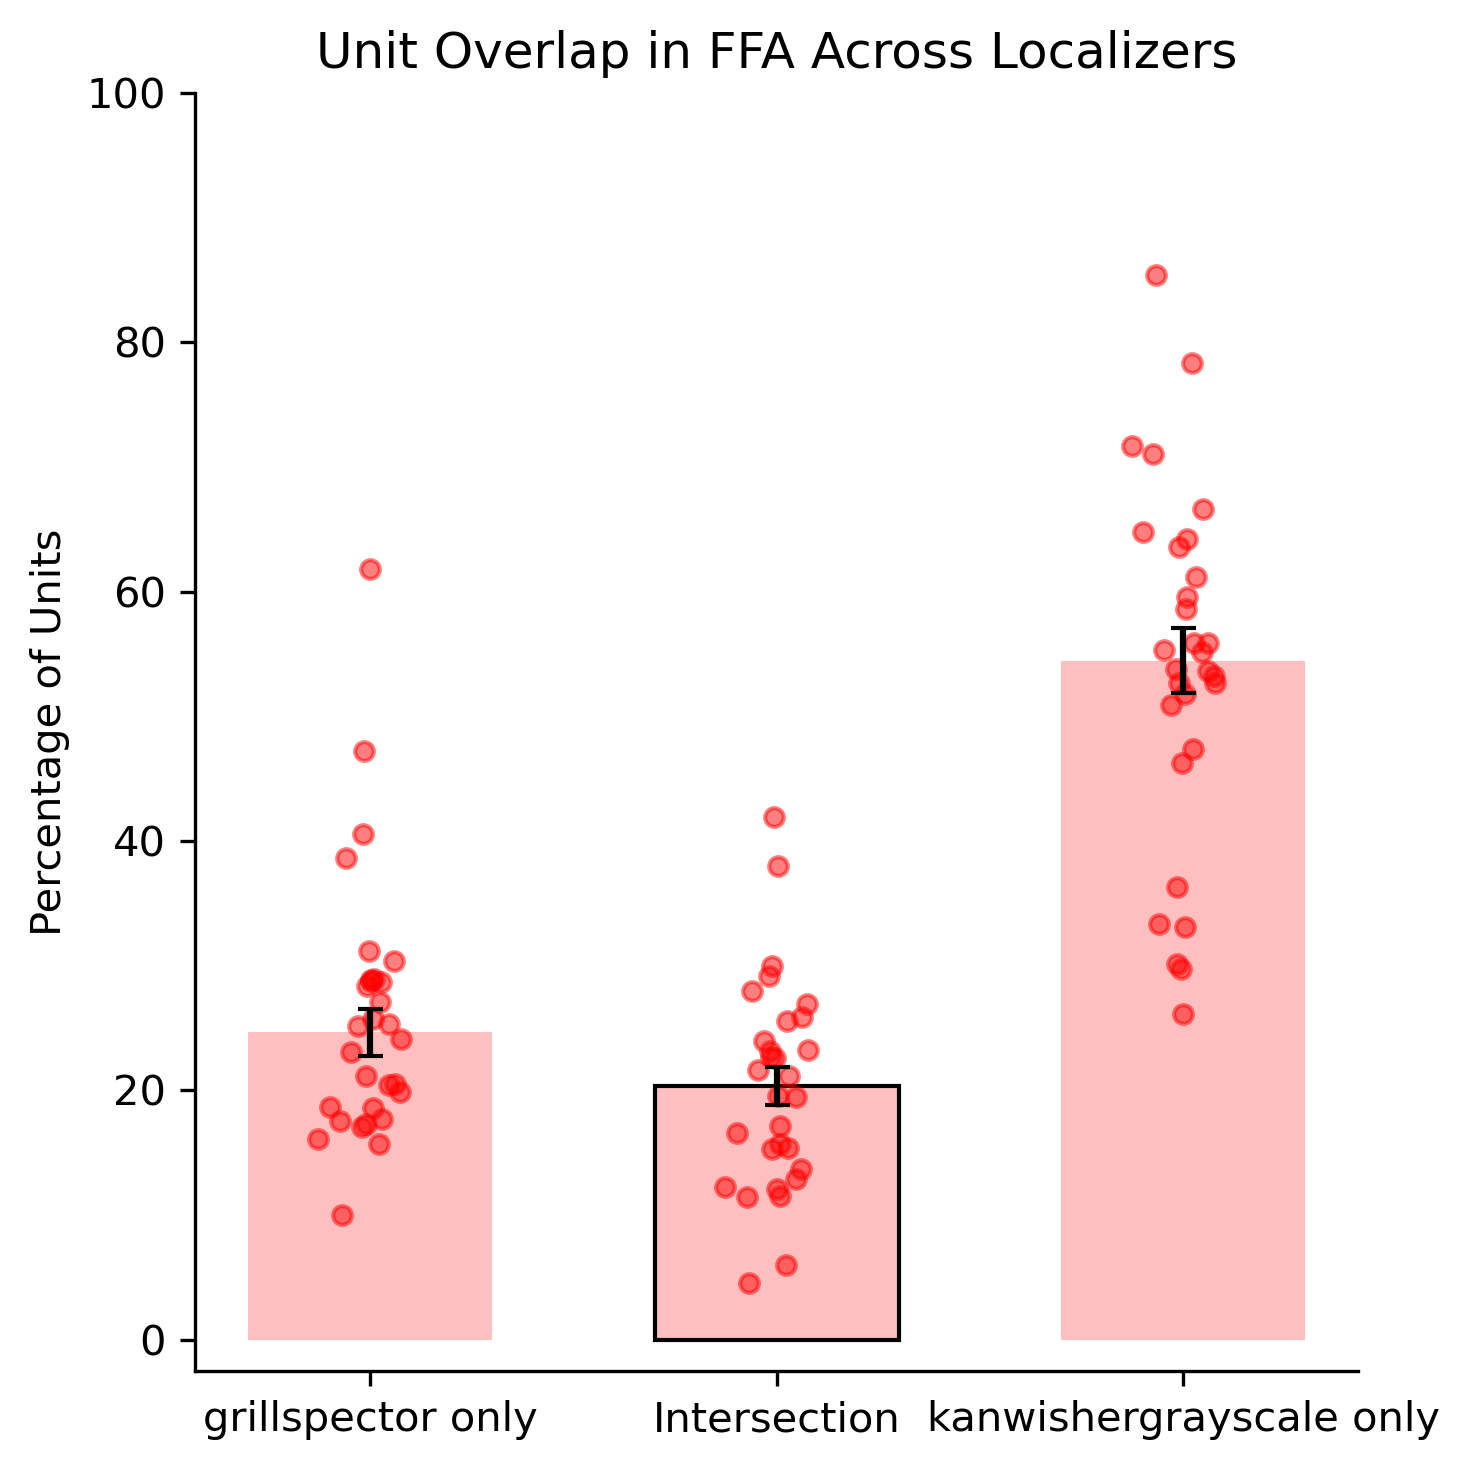

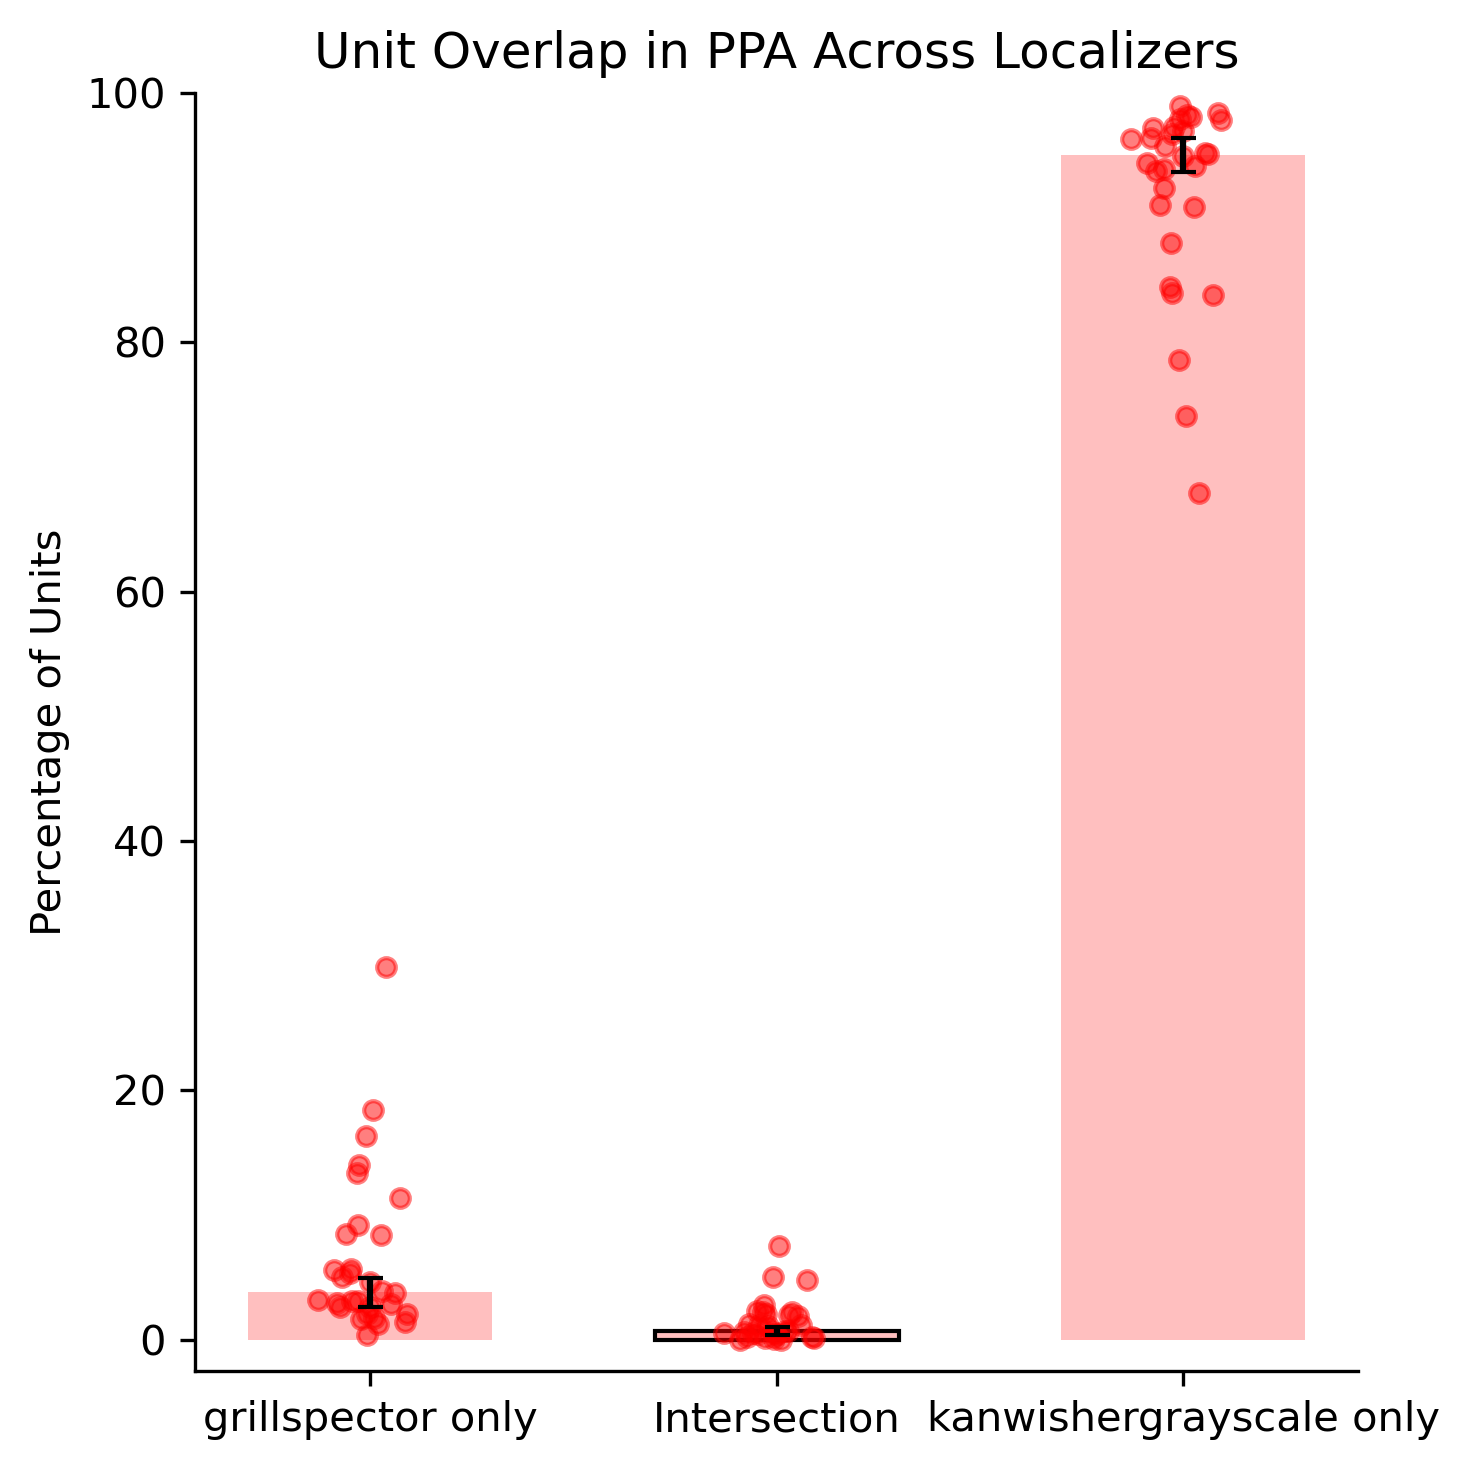

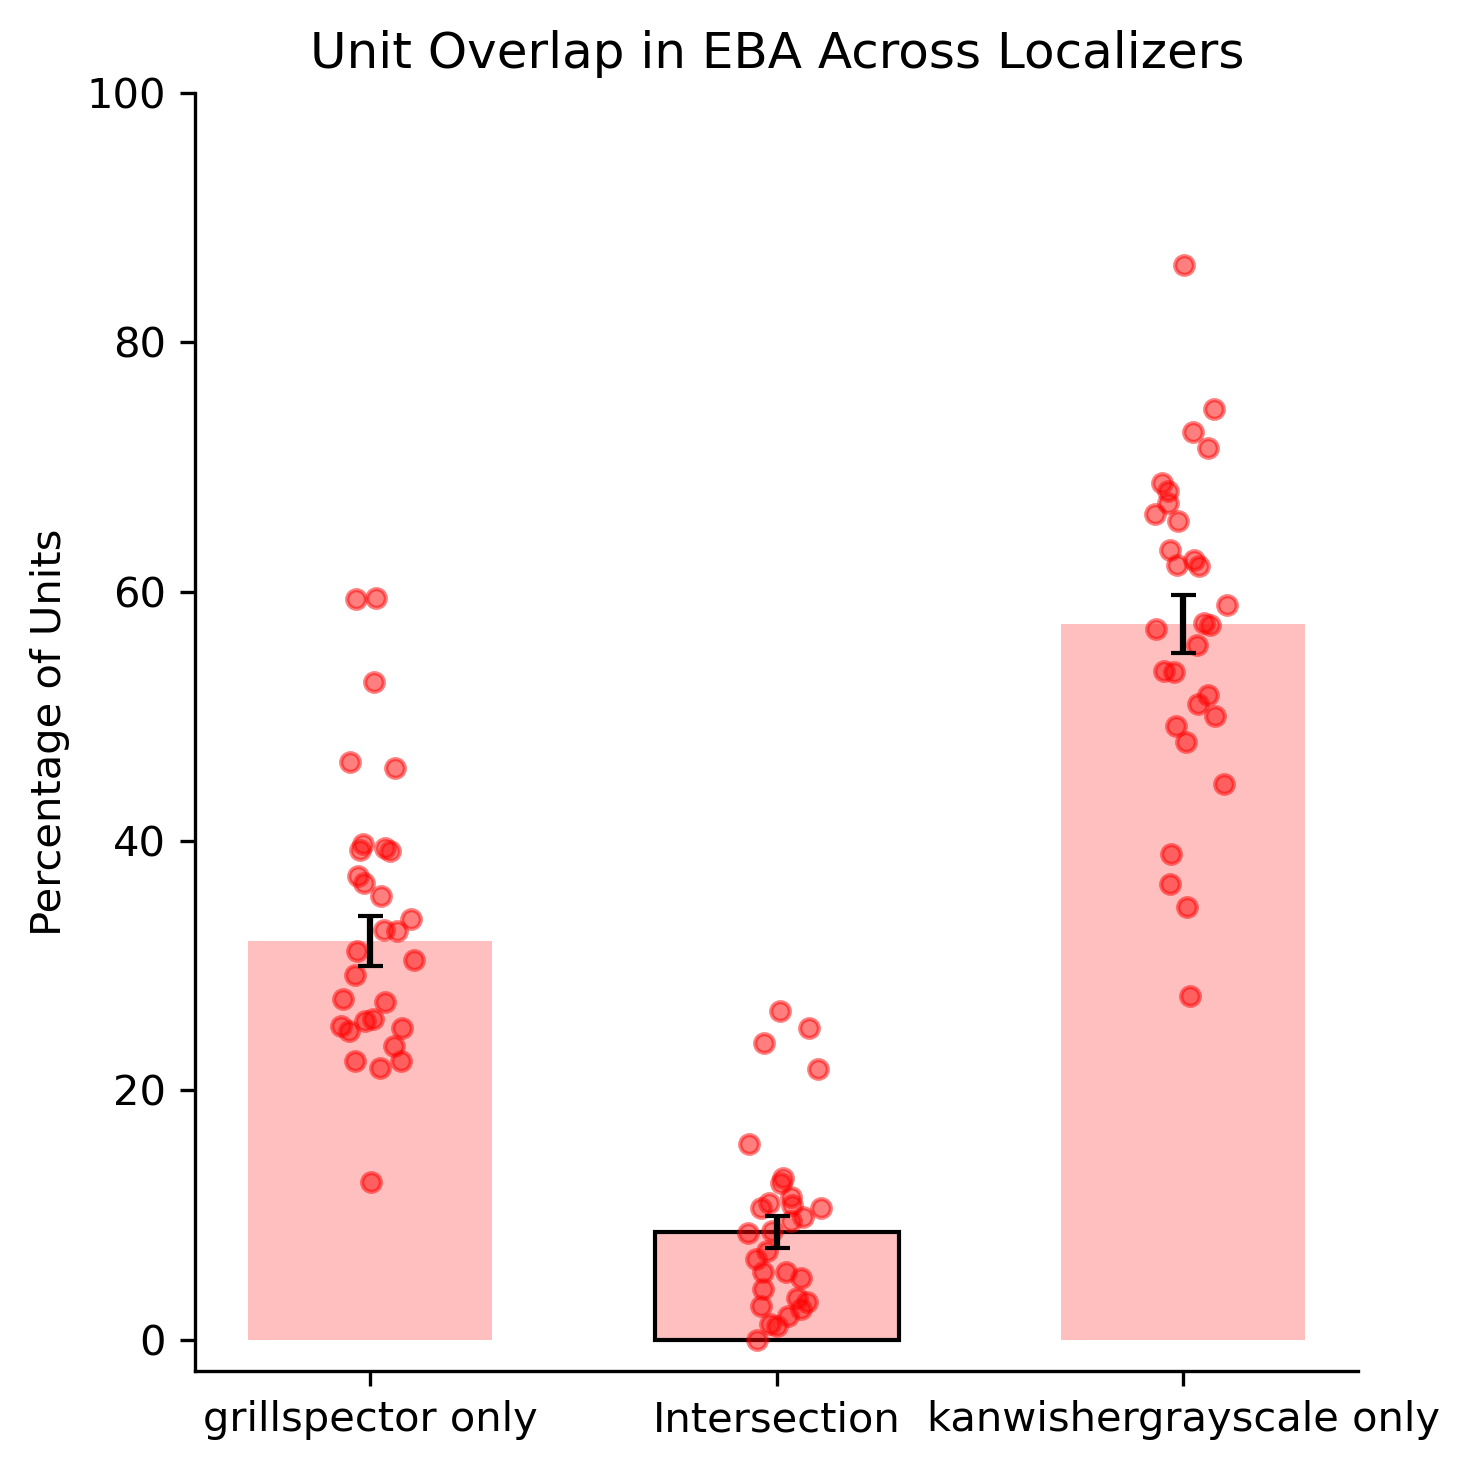

In [ ]:
# Grill-Spector vs Kanwisher Grayscale

plot_dir = f'{PLOTS_DIR}/localizer_effect'
os.makedirs(plot_dir, exist_ok=True)

frois = ['FFA', 'PPA', 'EBA']
tthreshold = 7
model_localizer1 = 'grillspector'
model_localizer2 = 'kanwishergrayscale'
model_localizers = [model_localizer1, model_localizer2]

for froi in frois:
    models_layers = ma.get_froi_models_layers(froi, froi)
    model_units = {}
    for model_name, layer in models_layers.items():
        model_units[model_name] = {}
        for model_localizer in model_localizers:
            results_json_dir = f'{MODELS_DIR}/{model_name}/{model_localizer}/{froi}/{layer}'
            results_json_name = f'results_{model_name}_{layer}_{froi}_{model_localizer}_{froi}_{tthreshold:.2f}.json'
            results_json_path = f'{results_json_dir}/{results_json_name}'
            with open(results_json_path, 'r') as f:
                results_json = json.load(f)
            model_units[model_name][model_localizer] = results_json['unit_indices']
    model_names = []
    percentage_units_localizer1 = []
    percentage_units_localizer2 = []
    percentage_units_intersection = []
    for model_name in model_units.keys():
        model_names.append(model_name)
        units_localizer1 = set(model_units[model_name][model_localizer1]) - \
                            set(model_units[model_name][model_localizer2])
        units_localizer2 = set(model_units[model_name][model_localizer2]) - \
                            set(model_units[model_name][model_localizer1])
        units_intersection = set(model_units[model_name][model_localizer1]).intersection(
            set(model_units[model_name][model_localizer2])
        )
        units_union = set(model_units[model_name][model_localizer1]).union(
            set(model_units[model_name][model_localizer2])
        )
        percentage_units_localizer1.append(len(units_localizer1) / len(units_union) * 100)
        percentage_units_localizer2.append(len(units_localizer2) / len(units_union) * 100)
        percentage_units_intersection.append(len(units_intersection) / len(units_union) * 100)
        # print(
        #     f'{model_name}: {percentage_units_localizer1[-1]:.2f}%, {percentage_units_localizer2[-1]:.2f}%, '
        #     f'{percentage_units_intersection[-1]:.2f}%'
        # )
    
    # Create a DataFrame to store the results
    results_df = pd.DataFrame({
        'model_name': model_names,
        f'{model_localizer1}_only': percentage_units_localizer1,
        f'{model_localizer2}_only': percentage_units_localizer2,
        'intersection': percentage_units_intersection
    })
    
    # Calculate statistics for plotting
    medians = [
        np.median(percentage_units_localizer1),
        np.median(percentage_units_intersection),
        np.median(percentage_units_localizer2)
    ]
    sems = [
        np.std(percentage_units_localizer1) / np.sqrt(len(percentage_units_localizer1)),
        np.std(percentage_units_intersection) / np.sqrt(len(percentage_units_intersection)),
        np.std(percentage_units_localizer2) / np.sqrt(len(percentage_units_localizer2))
    ]
    
    # Set up the figure
    fig, ax = plt.figure(figsize=(5, 5), dpi=300), plt.gca()
    width = 0.6
    x = np.array([0, 1, 2])
    
    # Create the bar plot with error bars
    bars = ax.bar(x, medians, width=width, color=(1, 0, 0, 0.25), yerr=sems, capsize=3)
    # Highlight intersection
    bars[1].set_edgecolor('black')
    bars[1].set_linewidth(1)
    
    # Add jittered points
    jitter = 0.05
    jitter_vals = np.random.normal(0, jitter, len(model_names))
    for i, (percentages, pos) in enumerate(zip([percentage_units_localizer1, percentage_units_intersection, percentage_units_localizer2], x)):
        jittered_x = pos + jitter_vals
        ax.scatter(jittered_x, percentages, color='r', alpha=0.5, s=20)
    
    # Connect points across bars with gray lines
    # for i in range(len(model_names)):
    #     loc1_percentage = percentage_units_localizer1[i]
    #     loc2_percentage = percentage_units_localizer2[i]
    #     intersection_percentage = percentage_units_intersection[i]
    #     assert np.isclose(loc1_percentage + loc2_percentage + intersection_percentage, 100, atol=0.1), f"Mismatch in percentages for {model_names[i]}"
    #     plt.plot([
    #         0 + jitter_vals[i], 1 + jitter_vals[i], 2 + jitter_vals[i]
    #     ], 
    #         [percentage_units_localizer1[i], percentage_units_intersection[i], percentage_units_localizer2[i]],
    #         'grey', alpha=0.3, linestyle='-', linewidth=0.5)
    
    # Customize the plot
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{model_localizer1} only', 'Intersection', f'{model_localizer2} only'])
    ax.set_ylabel('Percentage of Units')
    ax.set_title(f'Unit Overlap in {froi} Across Localizers')

    # Limits, ticks and tight layout
    ax.set_ylim(-2.5, 100)
    ax.set_yticks(np.arange(0, 101, 20))
    plt.tight_layout()
    
    # Show the plot
    plt.show()

    # Save the figure
    # plt.savefig(f'{plot_dir}/localizer_intersection_{froi}.pdf')
    # plt.close()
    
    # Save the data for further analysis
    # results_df.to_csv(f'{plot_dir}/localizer_intersection_{froi}.csv', index=False)

# Effect of t-threshold

In [29]:
plot_dir = f'{PLOTS_DIR}/tthreshold_effect'
os.makedirs(plot_dir, exist_ok=True)

tthreshold_effect_csv = pd.read_csv(TTHRESHOLDEFFECT_CSV_PATH)
tthresholds = tthreshold_effect_csv['model_tthreshold'].unique()

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

frois = tthreshold_effect_csv['model_froi'].unique()

for froi in frois:
        # Filter data for the specified froi
        froi_data = tthreshold_effect_csv[tthreshold_effect_csv['model_froi'] == froi]
        subject_froi_data = subjectsubject_correlations_csv[subjectsubject_correlations_csv['fmri_froi'] == froi]

        # Set up the figure
        plt.figure(figsize=(10, 6), dpi=300)

        # Define colors for different model_tthresholds
        colors = plt.cm.Reds(np.linspace(0, 1, len(tthresholds)+2)[2:]) # Avoid white and black

        # For each model_tthreshold, plot the median normed_pearsonr across fmri_tthresholds
        for i, model_tthreshold in enumerate(tthresholds):
                threshold_data = froi_data[froi_data['model_tthreshold'] == model_tthreshold]

                # Group by fmri_tthreshold and calculate median and SEM
                grouped_data = threshold_data.groupby('fmri_tthreshold')['normed_pearsonr'].agg(['median', 'sem']).reset_index()

                # Plot line with median values
                plt.plot(grouped_data['fmri_tthreshold'], grouped_data['median'], 
                        marker='o', color=colors[i], mfc=colors[i], label=f'Model t>{model_tthreshold}', mec='k')

                # Add shaded area for SEM
                plt.fill_between(grouped_data['fmri_tthreshold'], 
                                grouped_data['median'] - grouped_data['sem'],
                                grouped_data['median'] + grouped_data['sem'],
                                color=colors[i], alpha=0.2)
        
        # Plot subject-subject data
        subject_grouped_data = subject_froi_data.groupby('fmri_tthreshold')['normed_pearsonr'].agg(['median', 'sem']).reset_index()
        plt.plot(subject_grouped_data['fmri_tthreshold'], subject_grouped_data['median'],
                marker='o', mfc='blue', label='Subject-Subject', linestyle='--', mec='k')
        plt.fill_between(subject_grouped_data['fmri_tthreshold'],
                        subject_grouped_data['median'] - subject_grouped_data['sem'],
                        subject_grouped_data['median'] + subject_grouped_data['sem'],
                        color='blue', alpha=0.2)

        # Customize plot
        plt.xlabel('fMRI t-threshold')
        plt.ylabel('Median Normalized Pearson r')
        plt.title(f'Effect of t-threshold on {froi} Representation Correlation')
        # plt.grid(True, linestyle='--', alpha=0.7)
        plt.legend(title='Model t-threshold')
        plt.xticks(tthresholds)
        plt.ylim(0, 1.05)

        # Remove top and right spines
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)

        # Save the figure
        plt.savefig(f'{plot_dir}/tthreshold_effect_{froi}_normed_pearsonr.pdf')
        plt.close()

        # Repeat for normed_rdmr
        plt.figure(figsize=(10, 6), dpi=300)

        for i, model_tthreshold in enumerate(tthresholds):
                threshold_data = froi_data[froi_data['model_tthreshold'] == model_tthreshold]
                grouped_data = threshold_data.groupby('fmri_tthreshold')['normed_rdmr'].agg(['median', 'sem']).reset_index()

                plt.plot(grouped_data['fmri_tthreshold'], grouped_data['median'], 
                        marker='o', color=colors[i], mfc=colors[i], label=f'Model t>{model_tthreshold}', mec='k')

                plt.fill_between(grouped_data['fmri_tthreshold'], 
                                grouped_data['median'] - grouped_data['sem'],
                                grouped_data['median'] + grouped_data['sem'],
                                color=colors[i], alpha=0.2)

        # Plot subject-subject data
        subject_grouped_data = subject_froi_data.groupby('fmri_tthreshold')['normed_rdmr'].agg(['median', 'sem']).reset_index()
        plt.plot(subject_grouped_data['fmri_tthreshold'], subject_grouped_data['median'],
                marker='o', mfc='blue', label='Subject-Subject', linestyle='--', mec='k')
        plt.fill_between(subject_grouped_data['fmri_tthreshold'],
                        subject_grouped_data['median'] - subject_grouped_data['sem'],
                        subject_grouped_data['median'] + subject_grouped_data['sem'],
                        color='blue', alpha=0.2)

        plt.xlabel('fMRI t-threshold')
        plt.ylabel('Median Normalized RDM r')
        plt.title(f'Effect of t-threshold on {froi} Multivariate Correlation')
        # plt.grid(True, linestyle='--', alpha=0.7)
        plt.legend(title='Model t-threshold')
        plt.xticks(tthresholds)
        plt.ylim(0, 1.25)

        # Remove top and right spines
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)

        plt.savefig(f'{plot_dir}/tthreshold_effect_{froi}_normed_rdmr.pdf')
        plt.close()